# Solar Power Generation Forecasting By ANN



## importing libraries

In [3]:
import pandas as pd
import numpy as np
import tensorflow as tf
from keras.layers import Dense, Activation, BatchNormalization, Dropout
from keras import regularizers
from keras.optimizers import RMSprop, Adam, SGD
import datetime
import matplotlib.pyplot as plt
import seaborn as sns

## importing dataset

In [5]:

#data_path = r'drive/My Drive/Proj/S.P.F./solarpowergeneration.csv'
dts = pd.read_csv('solarpowergeneration.csv')
dts.head(10)

,temperature_2_m_above_gnd,relative_humidity_2_m_above_gnd,mean_sea_level_pressure_MSL,total_precipitation_sfc,snowfall_amount_sfc,total_cloud_cover_sfc,high_cloud_cover_high_cld_lay,medium_cloud_cover_mid_cld_lay,low_cloud_cover_low_cld_lay,shortwave_radiation_backwards_sfc,...,wind_direction_10_m_above_gnd,wind_speed_80_m_above_gnd,wind_direction_80_m_above_gnd,wind_speed_900_mb,wind_direction_900_mb,wind_gust_10_m_above_gnd,angle_of_incidence,zenith,azimuth,generated_power_kw
0,2.17,31,1035.0,0.0,0.0,0.0,0,0,0,0.00,...,312.71,9.36,22.62,6.62,337.62,24.48,58.753108,83.237322,128.33543,454.100950
1,2.31,27,1035.1,0.0,0.0,0.0,0,0,0,1.78,...,294.78,5.99,32.74,4.61,321.34,21.96,45.408585,75.143041,139.65530,1411.999400
2,3.65,33,1035.4,0.0,0.0,0.0,0,0,0,108.58,...,270.00,3.89,56.31,3.76,286.70,14.04,32.848282,68.820648,152.53769,2214.849300
3,5.82,30,1035.4,0.0,0.0,0.0,0,0,0,258.10,...,323.13,3.55,23.96,3.08,339.44,19.80,22.699288,64.883536,166.90159,2527.609200
4,7.73,27,1034.4,0.0,0.0,0.0,0,0,0,375.58,...,10.01,6.76,25.20,6.62,22.38,16.56,19.199908,63.795208,182.13526,2640.203400
5,8.69,29,1034.6,0.0,0.0,0.0,0,0,0,449.45,...,23.63,7.10,30.47,6.92,27.90,17.28,25.088167,65.700860,197.22062,2546.081600
6,9.72,27,1034.0,0.0,0.0,0.0,0,0,0,469.92,...,25.02,6.61,29.36,6.44,26.57,12.96,36.197514,70.351498,211.21422,2270.320700
7,10.07,28,1034.1,0.0,0.0,0.0,0,0,0,436.99,...,14.74,7.63,19.29,7.52,16.70,10.80,49.073008,77.228779,223.65641,1063.830200
8,9.38,32,1033.9,0.0,0.0,0.0,0,0,0,353.33,...,6.58,10.50,5.91,10.14,6.12,11.52,62.371140,85.585411,234.50308,86.817611
9,6.54,47,1035.1,0.0,0.0,0.0,0,0,0,228.73,...,360.00,12.25,1.68,11.53,1.79,12.24,105.866560,121.463180,216.06756,9.666667


In [6]:
X = dts.iloc[:, :-1].values
y = dts.iloc[:, -1].values
print(X.shape, y.shape)
y = np.reshape(y, (-1,1))
y.shape

(4213, 20) (4213,)


(4213, 1)

In [7]:
X

array([[   2.17    ,   31.      , 1035.      , ...,   58.753108,
          83.237322,  128.33543 ],
       [   2.31    ,   27.      , 1035.1     , ...,   45.408585,
          75.143041,  139.6553  ],
       [   3.65    ,   33.      , 1035.4     , ...,   32.848282,
          68.820648,  152.53769 ],
       ...,
       [   7.27    ,   90.      , 1026.3     , ...,   25.249506,
          65.827032,  197.33868 ],
       [   8.25    ,   81.      , 1025.5     , ...,   36.361161,
          70.496313,  211.30027 ],
       [   8.      ,   80.      , 1025.3     , ...,   48.452849,
          76.919574,  223.04931 ]])

In [8]:
y

array([[ 454.10095 ],
       [1411.9994  ],
       [2214.8493  ],
       ...,
       [ 158.36778 ],
       [ 126.95306 ],
       [  20.055031]])

## Splitting Training and Test sets

In [9]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)
print("Train Shape: {} {} \nTest Shape: {} {}".format(X_train.shape, y_train.shape, X_test.shape, y_test.shape))

Train Shape: (3159, 20) (3159, 1) 
Test Shape: (1054, 20) (1054, 1)


## Feature Scaling

In [10]:
from sklearn.preprocessing import StandardScaler
# input scaling
sc_X = StandardScaler()
X_train = sc_X.fit_transform(X_train)
X_test = sc_X.transform(X_test)

# outcome scaling:
sc_y = StandardScaler()
y_train = sc_y.fit_transform(y_train)
y_test = sc_y.transform(y_test)

In [11]:
X_train

array([[-0.15688663, -0.65066193,  0.32458773, ..., -1.17016507,
         0.20906612,  0.23973116],
       [-0.96299273,  1.26236489, -0.09488224, ...,  0.21285162,
         1.10270022, -0.59126299],
       [-0.01104135, -0.22554486, -1.44007902, ..., -0.78166945,
        -1.98808451, -0.32872643],
       ...,
       [ 0.08053592, -0.39559169, -0.65899702, ..., -1.39867408,
        -1.07235309, -0.0910784 ],
       [ 0.34283131, -0.90573217,  0.59941288, ..., -0.46582577,
         0.41541699,  0.76311909],
       [-0.6893915 ,  0.62468928,  1.45281728, ...,  0.28508139,
         0.20437129, -0.90996355]])

In [12]:
X_test

array([[ 0.34735364, -1.37336095,  0.58494839, ..., -0.78124559,
        -0.35197112,  0.78338018],
       [-1.93190285,  1.68748196, -0.84703527, ...,  0.34119265,
         1.11388012, -0.66875224],
       [-0.95055631,  0.28459563,  0.97548939, ...,  0.32973403,
        -0.38653881, -1.09819031],
       ...,
       [ 0.69783455, -1.37336095,  1.09120525, ..., -0.47407508,
         0.36095606,  0.77638555],
       [-0.00991077, -1.6709429 ,  1.93014517, ..., -1.21521633,
         0.12748879,  0.27526625],
       [-0.58537781,  1.00729465, -1.0640025 , ...,  0.07094803,
         0.619908  , -0.66549089]])

In [13]:
y_train

array([[ 0.37304328],
       [-0.96068338],
       [ 0.56242648],
       ...,
       [ 1.74385844],
       [-0.58299753],
       [-0.14116491]])

## Creating Neural Network

In [14]:
def create_spfnet(n_layers, n_activation, kernels):
  model = tf.keras.models.Sequential()
  for i, nodes in enumerate(n_layers):
    if i==0:
      model.add(Dense(nodes, kernel_initializer=kernels, activation=n_activation, input_dim=X_train.shape[1]))
    else:
      model.add(Dense(nodes, activation=n_activation, kernel_initializer=kernels))

  model.add(Dense(1))
  model.compile(loss='mse',
                optimizer='adam',
                metrics=[tf.keras.metrics.RootMeanSquaredError()])
  return model


In [15]:
spfnet = create_spfnet([32, 64], 'relu', 'normal')
spfnet.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense (Dense)               (None, 32)                672       
                                                                 
 dense_1 (Dense)             (None, 64)                2112      
                                                                 
 dense_2 (Dense)             (None, 1)                 65        
                                                                 
Total params: 2849 (11.13 KB)
Trainable params: 2849 (11.13 KB)
Non-trainable params: 0 (0.00 Byte)
_________________________________________________________________


In [16]:
hist = spfnet.fit(X_train, y_train, batch_size=32, validation_data=(X_test, y_test),epochs=150, verbose=2)

Epoch 1/150
99/99 - 2s - loss: 0.4747 - root_mean_squared_error: 0.6890 - val_loss: 0.2674 - val_root_mean_squared_error: 0.5171 - 2s/epoch - 15ms/step
Epoch 2/150
99/99 - 0s - loss: 0.2523 - root_mean_squared_error: 0.5023 - val_loss: 0.2528 - val_root_mean_squared_error: 0.5028 - 232ms/epoch - 2ms/step
Epoch 3/150
99/99 - 0s - loss: 0.2410 - root_mean_squared_error: 0.4910 - val_loss: 0.2513 - val_root_mean_squared_error: 0.5013 - 234ms/epoch - 2ms/step
Epoch 4/150
99/99 - 0s - loss: 0.2315 - root_mean_squared_error: 0.4811 - val_loss: 0.2434 - val_root_mean_squared_error: 0.4933 - 234ms/epoch - 2ms/step
Epoch 5/150
99/99 - 0s - loss: 0.2242 - root_mean_squared_error: 0.4735 - val_loss: 0.2390 - val_root_mean_squared_error: 0.4889 - 230ms/epoch - 2ms/step
Epoch 6/150
99/99 - 0s - loss: 0.2206 - root_mean_squared_error: 0.4697 - val_loss: 0.2273 - val_root_mean_squared_error: 0.4767 - 236ms/epoch - 2ms/step
Epoch 7/150
99/99 - 0s - loss: 0.2148 - root_mean_squared_error: 0.4634 - val_

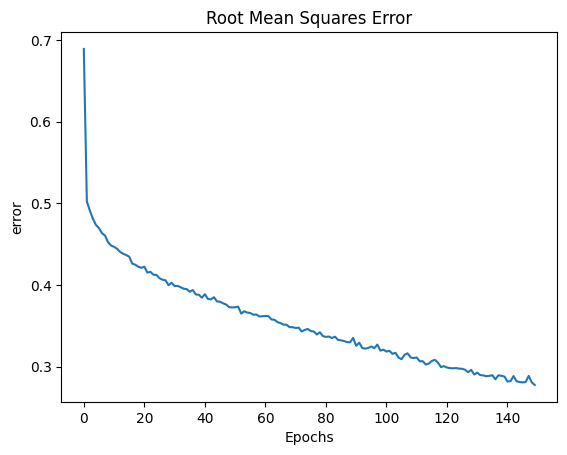

In [17]:
plt.plot(hist.history['root_mean_squared_error'])
plt.title('Root Mean Squares Error')
plt.xlabel('Epochs')
plt.ylabel('error')
plt.show()

In [18]:
spfnet.evaluate(X_train, y_train)

99/99 [==============================] - 0s 1ms/step - loss: 0.0779 - root_mean_squared_error: 0.2791


[0.07787841558456421, 0.2790670394897461]

In [19]:
from sklearn.metrics import mean_squared_error

y_pred = spfnet.predict(X_test) # get model predictions (scaled inputs here)
y_pred_orig = sc_y.inverse_transform(y_pred) # unscale the predictions
y_test_orig = sc_y.inverse_transform(y_test) # unscale the true test outcomes

RMSE_orig = mean_squared_error(y_pred_orig, y_test_orig, squared=False)
RMSE_orig

33/33 [==============================] - 0s 1ms/step


468.92946530774367

In [20]:
train_pred = spfnet.predict(X_train) # get model predictions (scaled inputs here)
train_pred_orig = sc_y.inverse_transform(train_pred) # unscale the predictions
y_train_orig = sc_y.inverse_transform(y_train) # unscale the true train outcomes

mean_squared_error(train_pred_orig, y_train_orig, squared=False)

99/99 [==============================] - 0s 1ms/step


260.92297921761957

In [22]:
from sklearn.metrics import r2_score
from sklearn.metrics import mean_absolute_error

r2_score(y_pred_orig, y_test_orig)


0.7673948042823746

In [23]:
r2 = r2_score(y_test_orig, y_pred_orig)
print("r2 score : ",r2)

mae = mean_absolute_error(y_test_orig, y_pred_orig)
print("Mean Absolute Error (MAE):", mae)

mse = mean_squared_error(y_test_orig, y_pred_orig)
print("Mean Squared Error (MSE):", mse)

rmse = np.sqrt(mse)
print("Root Mean Squared Error (RMSE):", rmse)



r2 score :  0.7544653002828579
Mean Absolute Error (MAE): 302.8331457667874
Mean Squared Error (MSE): 219894.84343380635
Root Mean Squared Error (RMSE): 468.92946530774367


Text(0.5, 1.0, 'Test Predictions vs Real Data')

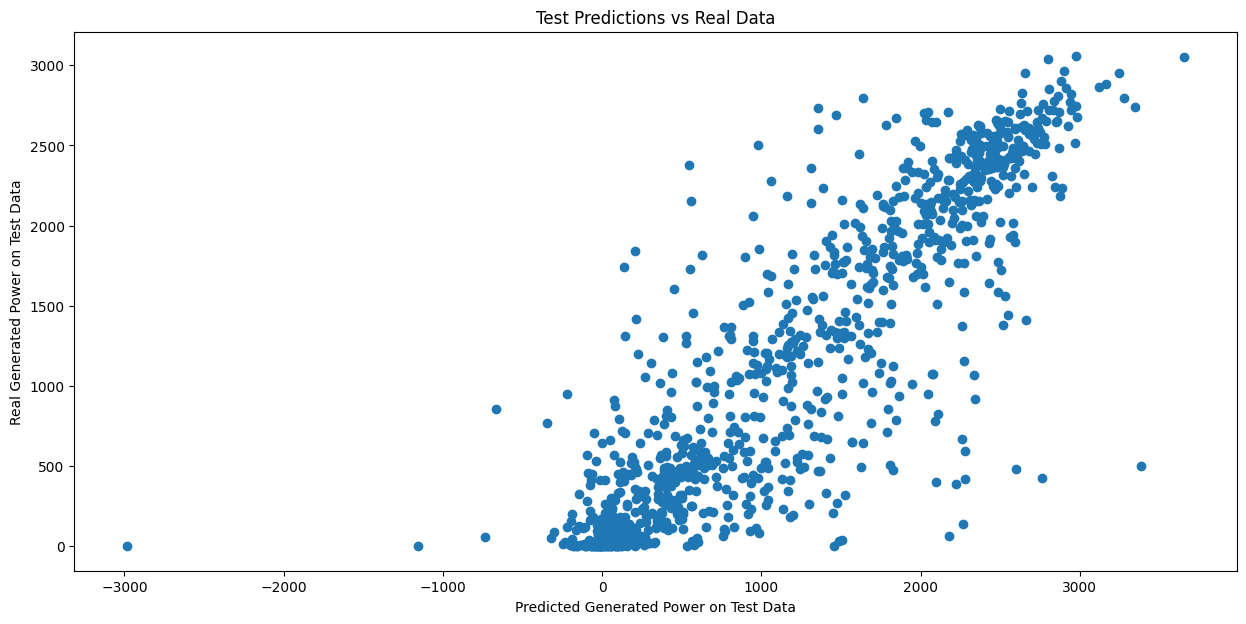

In [24]:
plt.figure(figsize=(15,7))
plt.scatter(y_pred_orig, y_test_orig)
plt.xlabel('Predicted Generated Power on Test Data')
plt.ylabel('Real Generated Power on Test Data')
plt.title('Test Predictions vs Real Data')


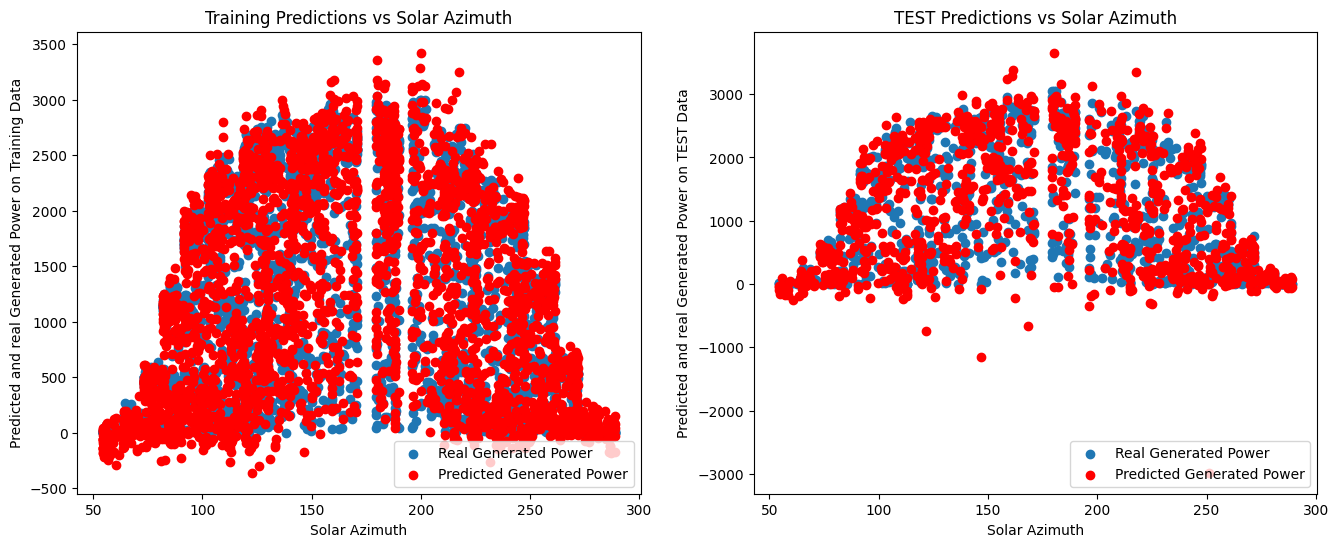

In [25]:
x_axis = sc_X.inverse_transform(X_train)[:,-1]
x2_axis = sc_X.inverse_transform(X_test)[:,-1]
plt.figure(figsize=(16,6))
plt.subplot(1,2,1)
plt.scatter(x_axis, y_train_orig, label='Real Generated Power')
plt.scatter(x_axis, train_pred_orig, c='red', label='Predicted Generated Power')
plt.ylabel('Predicted and real Generated Power on Training Data')
plt.xlabel('Solar Azimuth')
plt.title('Training Predictions vs Solar Azimuth')
plt.legend(loc='lower right')

plt.subplot(1,2,2)
plt.scatter(x2_axis, y_test_orig, label='Real Generated Power')
plt.scatter(x2_axis, y_pred_orig, c='red', label='Predicted Generated Power')
plt.ylabel('Predicted and real Generated Power on TEST Data')
plt.xlabel('Solar Azimuth')
plt.title('TEST Predictions vs Solar Azimuth')
plt.legend(loc='lower right')
plt.show()

In [26]:
results = np.concatenate((y_test_orig, y_pred_orig), 1)
results = pd.DataFrame(data=results)
results.columns = ['Real Solar Power Produced', 'Predicted Solar Power']
pd.options.display.float_format = "{:,.2f}".format
results[7:18]

,Real Solar Power Produced,Predicted Solar Power
7,"2,497.53","2,621.37"
8,514.65,589.28
9,916.92,"1,396.79"
10,"1,911.95","2,089.98"
11,35.15,566.17
12,"2,449.04","2,607.11"
13,38.84,"1,507.77"
14,823.41,"2,108.57"
15,"2,274.65","2,337.81"
16,"1,123.40","1,188.43"


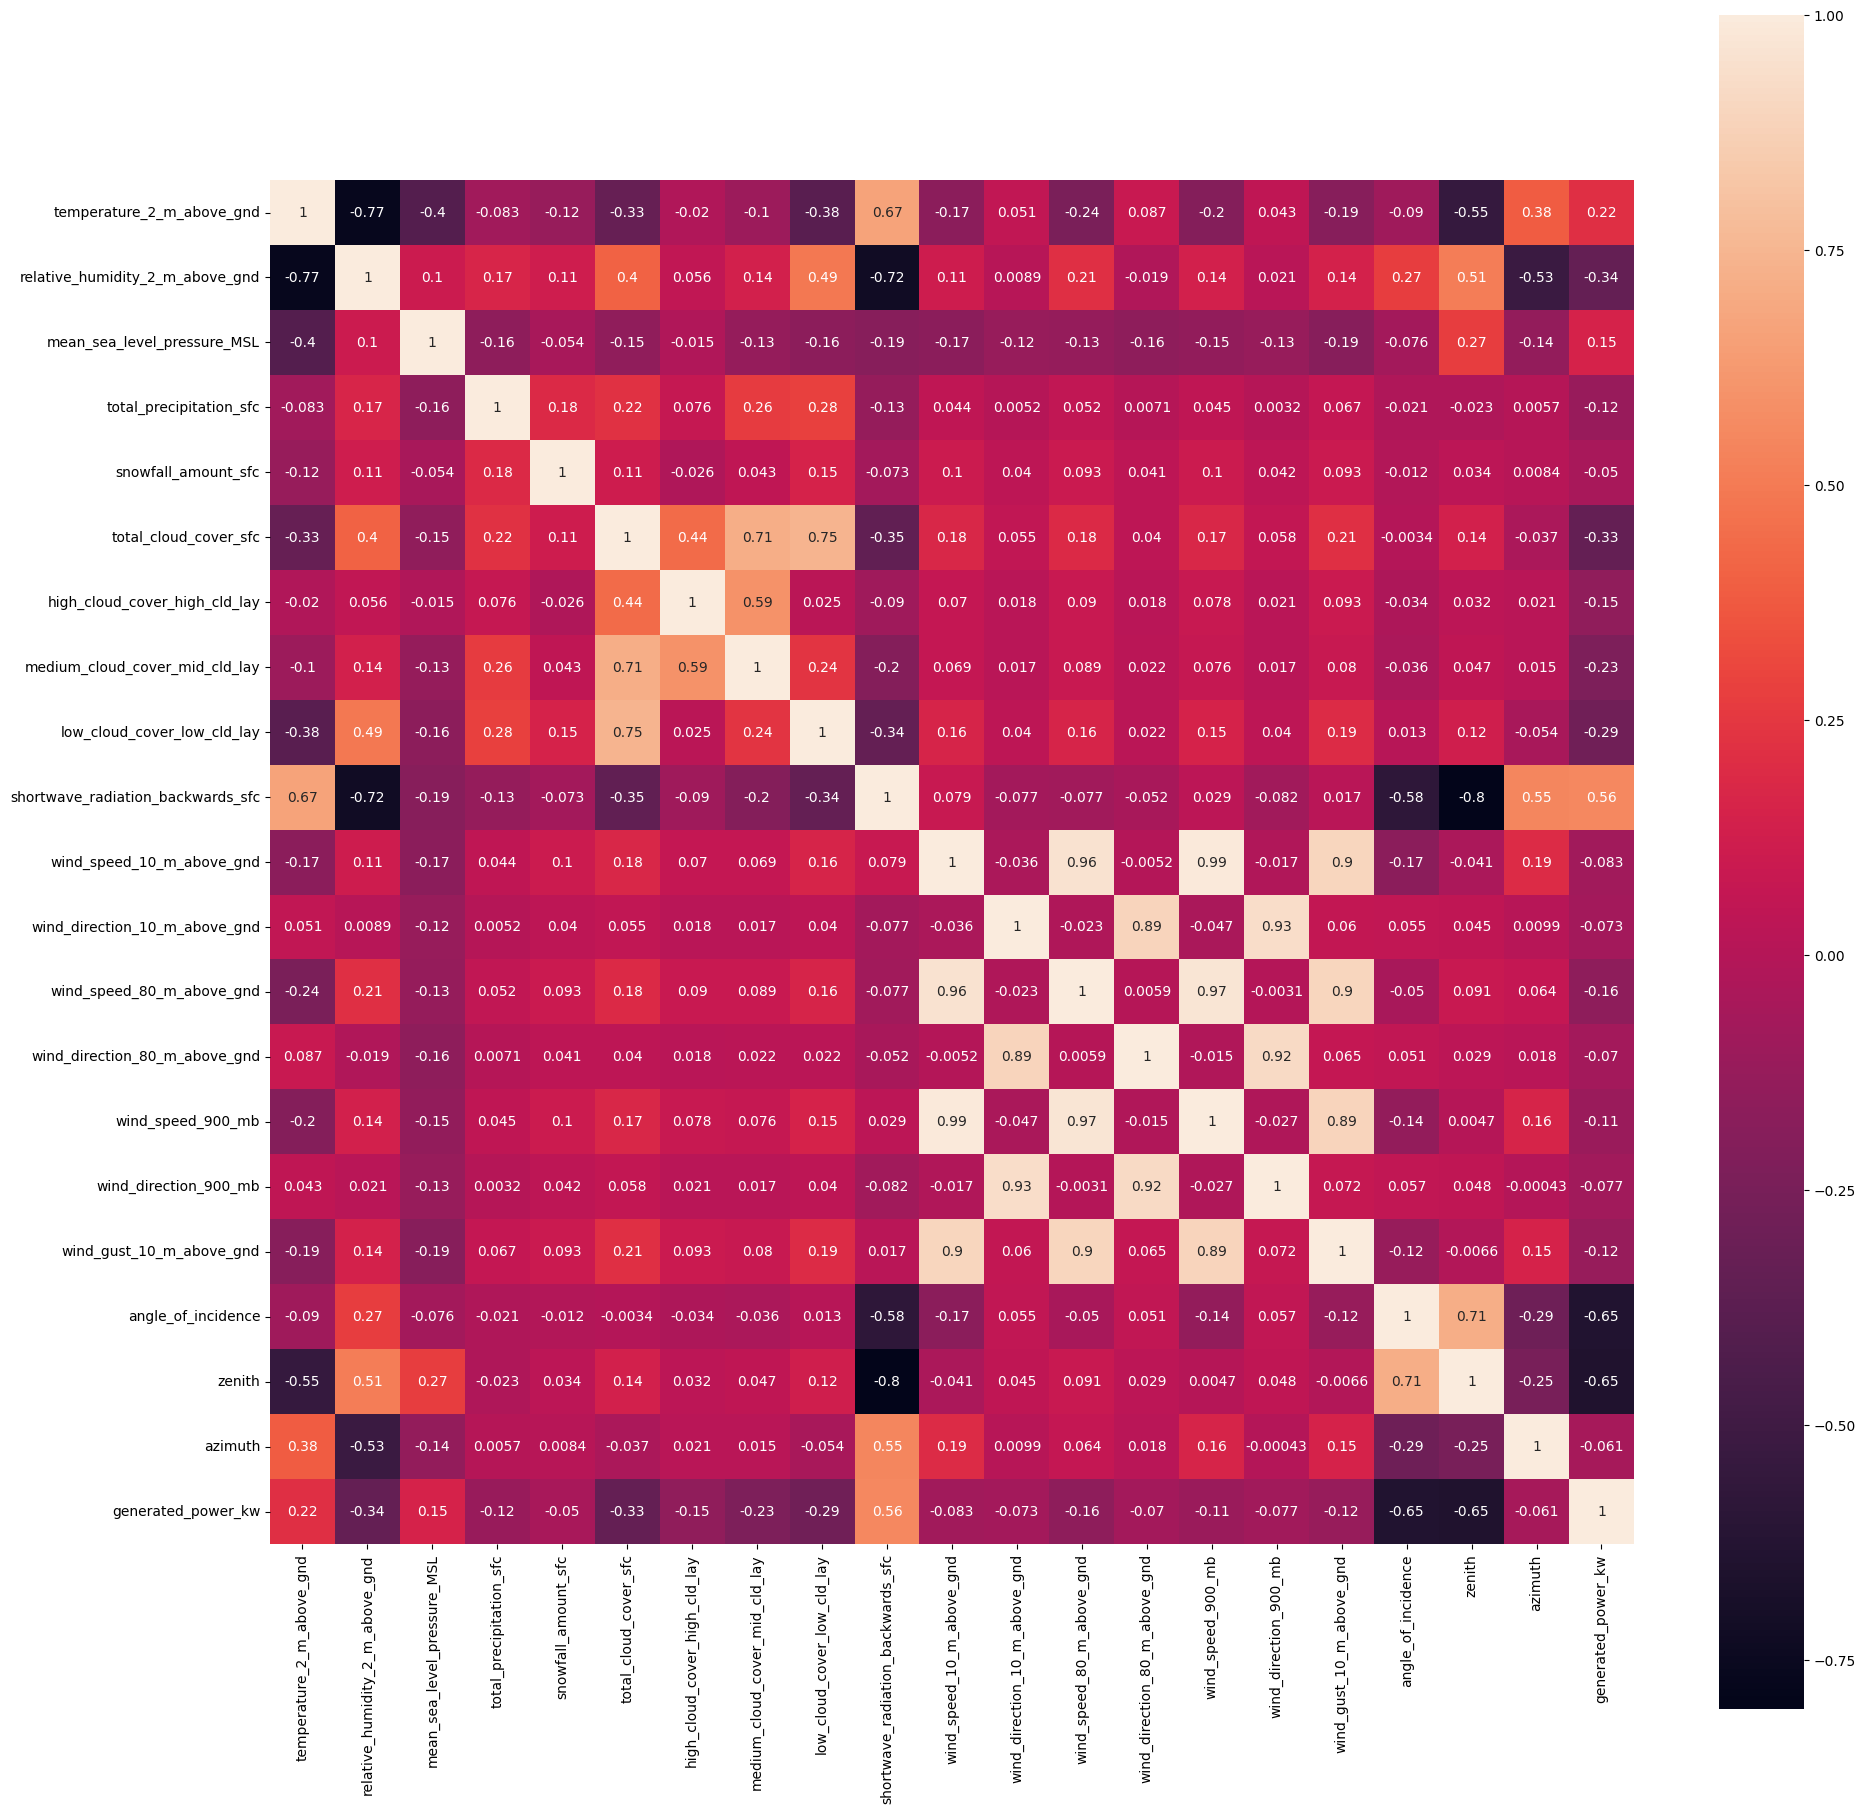

In [27]:
corr = dts.corr()
plt.figure(figsize=(22,22))
sns.heatmap(corr, annot=True, square=True);

**OBSERVATIONS**

- High Correlation between Zenith and Agnle of Incidence of 0.71
- Shortwave radiation backwards and Generate Power KW has corr of 0.56
- Relative Humidity and Zenith are +ve corr (0.51)
- Relative Humidity and Low Cloud Cover are + ve correlated (0.49)
- Angle of Incidence and Zenith are -vely correlated with Genarted Power (-0.65)
- -ve corr between Zenith and temperature of -0.55
- High negative corr exists btw Shortwave radiation backwards and Zenith (-.8)
- Shortwave radiation backwards and Relative humidity are -vely correlated (-.72)
- Relative humidity and Temperature are -vely correlated (-.77)
-


In [28]:
from sklearn.linear_model import Lasso
lasso = Lasso(alpha = 0.001)

lasso.fit(X_train, y_train)

y_pred_lasso = lasso.predict(X_test)

lasso_coeff = pd.DataFrame({'Feature Importance':lasso.coef_}, index=dts.columns[:-1])
lasso_coeff.sort_values('Feature Importance', ascending=False)

,Feature Importance
shortwave_radiation_backwards_sfc,0.38
mean_sea_level_pressure_MSL,0.12
wind_speed_80_m_above_gnd,0.07
wind_speed_10_m_above_gnd,0.02
snowfall_amount_sfc,0.02
wind_direction_80_m_above_gnd,0.01
wind_direction_10_m_above_gnd,0.01
wind_direction_900_mb,-0.00
total_precipitation_sfc,-0.00
wind_gust_10_m_above_gnd,-0.03


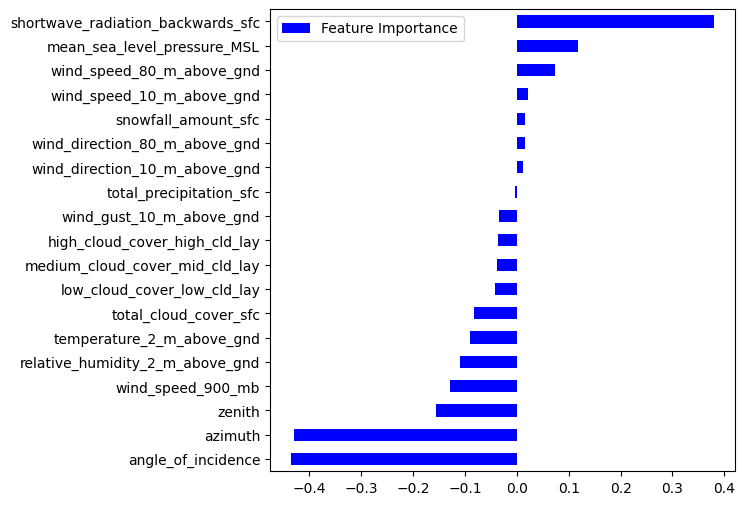

In [29]:
g = lasso_coeff[lasso_coeff['Feature Importance']!=0].sort_values('Feature Importance').plot(kind='barh',figsize=(6,6), cmap='winter')

In [30]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense
from sklearn.model_selection import train_test_split

# Assuming you have y_train data as well, make sure it has the appropriate shape.
# Split your data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X,y, test_size=0.2, random_state=42)  # Adjust the test_size and random_state as needed
# Define your model
model = Sequential()

# Add an LSTM layer with a specified number of units, input shape, and activation function.
model.add(LSTM(units=50, input_shape=(X_train.shape[1], 1), activation='tanh', return_sequences=True))

# Add a Dense layer for the output with an appropriate activation function.
model.add(Dense(units=1, activation='linear'))  # Change activation to match your problem type (e.g., 'linear', 'sigmoid', or 'softmax')

# Compile the model with the desired loss function, optimizer, and metrics.
model.compile(loss='mean_squared_error', optimizer='adam')

# Reshape X_train if it's a 2D array. LSTM expects a 3D input.
X_train = X_train.reshape(X_train.shape[0], X_train.shape[1], 1)

# Train the model
model.fit(X_train, y_train, epochs=100, batch_size=32)  # Adjust the number of epochs and batch size as needed.

# Make predictions
# Reshape X_test to match the input shape
X_test = X_test.reshape(X_test.shape[0], X_test.shape[1], 1)
y_pred = model.predict(X_test)

# Evaluate the model's performance if you have ground truth labels for testing (y_test).
# For regression problems, you can use mean squared error (MSE) or other appropriate metrics.
# For classification problems, you may use accuracy, precision, recall, etc.


Epoch 1/100
106/106 [==============================] - 3s 10ms/step - loss: 2152892.2500
Epoch 2/100
106/106 [==============================] - 1s 10ms/step - loss: 2128250.5000
Epoch 3/100
106/106 [==============================] - 1s 10ms/step - loss: 2112620.2500
Epoch 4/100
106/106 [==============================] - 1s 11ms/step - loss: 2099311.7500
Epoch 5/100
106/106 [==============================] - 2s 16ms/step - loss: 2086654.7500
Epoch 6/100
106/106 [==============================] - 2s 16ms/step - loss: 2074359.3750
Epoch 7/100
106/106 [==============================] - 1s 11ms/step - loss: 2062322.8750
Epoch 8/100
106/106 [==============================] - 1s 10ms/step - loss: 2050484.2500
Epoch 9/100
106/106 [==============================] - 1s 10ms/step - loss: 2038802.5000
Epoch 10/100
106/106 [==============================] - 1s 10ms/step - loss: 2027274.6250
Epoch 11/100
106/106 [==============================] - 1s 10ms/step - loss: 2015863.2500
Epoch 12/100
106/10

In [31]:
y_pred_2d = y_pred.reshape(-1, 1)
print(y_pred_2d)

y_test_2d = y_test.reshape(-1,1)
y_test_2d

print(y_pred_2d[:843].shape)
print(y_test_2d.shape)


[[398.43857]
 [501.70587]
 [517.5338 ]
 ...
 [520.0565 ]
 [520.0565 ]
 [520.0565 ]]
(843, 1)
(843, 1)


In [32]:
r2 = r2_score(y_test_2d, y_pred_2d[:843])
print("R-squared (R2) Score:", r2)

mae = mean_absolute_error(y_test_2d, y_pred_2d[:843])
print("Mean Absolute Error (MAE):", mae)

mse = mean_squared_error(y_test_2d, y_pred_2d[:843])
print("Mean Squared Error (MSE):", mse)

rmse = np.sqrt(mse)
print("Root Mean Squared Error (RMSE):", rmse)

R-squared (R2) Score: -0.41152660294939825
Mean Absolute Error (MAE): 889.4304439426184
Mean Squared Error (MSE): 1289378.4077927184
Root Mean Squared Error (RMSE): 1135.5079954772307


Text(0.5, 1.0, 'Test Predictions vs Real Data')

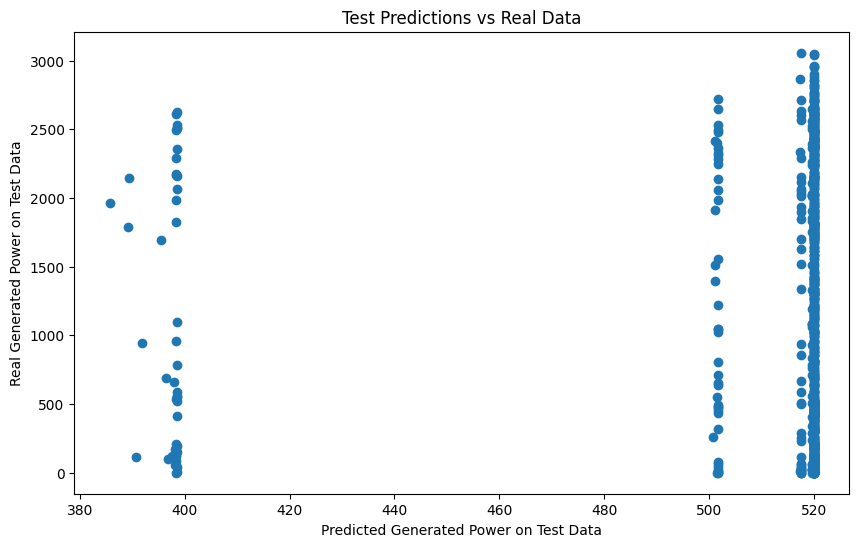

In [33]:
plt.figure(figsize=(10,6))
plt.scatter(y_pred_2d[:843], y_test_2d)
plt.xlabel('Predicted Generated Power on Test Data')
plt.ylabel('Real Generated Power on Test Data')
plt.title('Test Predictions vs Real Data')

In [51]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_squared_error, make_scorer
from sklearn.model_selection import GridSearchCV

# Split your data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X,y, test_size=0.2, random_state=42)  # Adjust the test_size and random_state as needed


# Reshape y to avoid DataConversionWarning
y_train = y_train.ravel()

# Define the parameter grid
param_grid = {
    'n_estimators': [50, 100, 150, 200],  # Adjust as needed
    'random_state': [42],  # Adjust as needed
}

# Create the RandomForestRegressor
rfr = RandomForestRegressor()

# Define R2 score as the evaluation metric for grid search
r2_scorer = make_scorer(r2_score)

# Perform Grid Search with Cross-Validation
grid_search = GridSearchCV(rfr, param_grid, cv=5, scoring=r2_scorer)
grid_search.fit(X_train, y_train)

# Print the best parameters
print("Best Parameters:", grid_search.best_params_)


Best Parameters: {'n_estimators': 200, 'random_state': 42}


In [52]:
# Create and train the Random Forest Regressor
rfr = RandomForestRegressor(n_estimators=200, random_state=42)  # You can adjust the number of estimators and other hyperparameters
rfr.fit(X_train, y_train)

# Make predictions on the test data
y_pred = rfr.predict(X_test)

# Calculate the R-squared (R2) score
r2 = r2_score(y_test, y_pred)
print("R-squared (R2) Score:", r2)

mae = mean_absolute_error(y_test, y_pred)
print("Mean Absolute Error (MAE):", mae)

# Calculate the Mean Squared Error (MSE)
mse = mean_squared_error(y_test, y_pred)
print("Mean Squared Error (MSE):", mse)

rmse = np.sqrt(mse)
print("Root Mean Squared Error (RMSE):", rmse)

R-squared (R2) Score: 0.8212306600912301
Mean Absolute Error (MAE): 253.7766204873272
Mean Squared Error (MSE): 163299.3146371384
Root Mean Squared Error (RMSE): 404.1030990194685


Text(0.5, 1.0, 'Test Predictions vs Real Data')

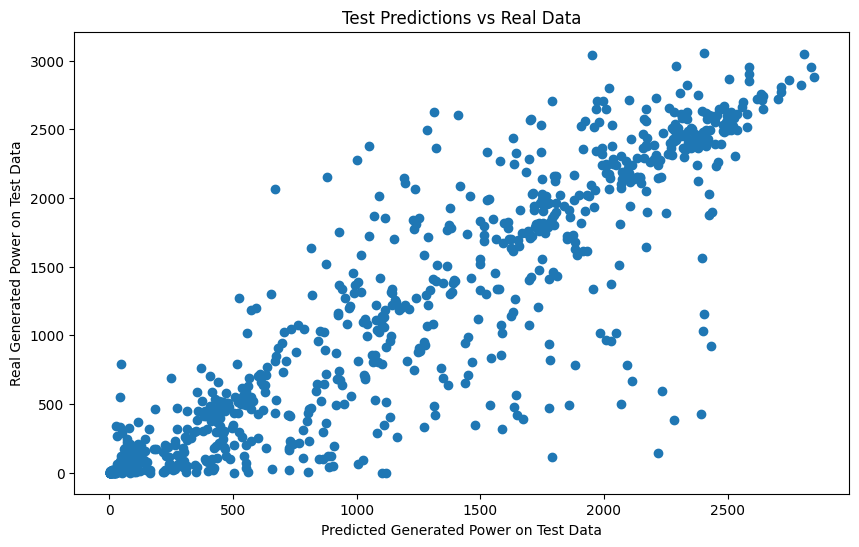

In [35]:
plt.figure(figsize=(10,6))
plt.scatter(y_pred, y_test)
plt.xlabel('Predicted Generated Power on Test Data')
plt.ylabel('Real Generated Power on Test Data')
plt.title('Test Predictions vs Real Data')

In [46]:
from sklearn.linear_model import ElasticNet
from sklearn.model_selection import GridSearchCV

# Split your data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)  # Adjust the test_size and random_state as needed


# Define the parameter grid
param_grid = {
    'alpha': [0.1, 0.5, 1.0, 2.0],
    'l1_ratio': [0.1, 0.3, 0.5, 0.7, 0.9]
}

# Create the Elastic Net model
elastic_net = ElasticNet()

# Perform Grid Search with Cross-Validation
grid_search = GridSearchCV(elastic_net, param_grid, cv=5)
grid_search.fit(X_train, y_train)

# Print the best parameters
print("Best Parameters:", grid_search.best_params_)



Best Parameters: {'alpha': 0.5, 'l1_ratio': 0.5}


ElasticNet(alpha=0.5)

In [47]:
# Create and train the Elastic Net Regression model
elastic_net = ElasticNet(alpha=0.5, l1_ratio=0.5)  # You can adjust alpha and l1_ratio as needed
elastic_net.fit(X_train, y_train)

# Make predictions on the test data
y_pred = elastic_net.predict(X_test)

# Calculate the R-squared (R2) score
r2 = r2_score(y_test, y_pred)
print("R-squared (R2) Score:", r2)

mae = mean_absolute_error(y_test, y_pred)
print("Mean Absolute Error (MAE):", mae)

# Calculate the Mean Squared Error (MSE)
mse = mean_squared_error(y_test, y_pred)
print("Mean Squared Error (MSE):", mse)

rmse = np.sqrt(mse)
print("Root Mean Squared Error (RMSE):", rmse)

R-squared (R2) Score: 0.7191748114671936
Mean Absolute Error (MAE): 390.65613527324587
Mean Squared Error (MSE): 256523.63455419784
Root Mean Squared Error (RMSE): 506.48162311598026


Text(0.5, 1.0, 'Test Predictions vs Real Data')

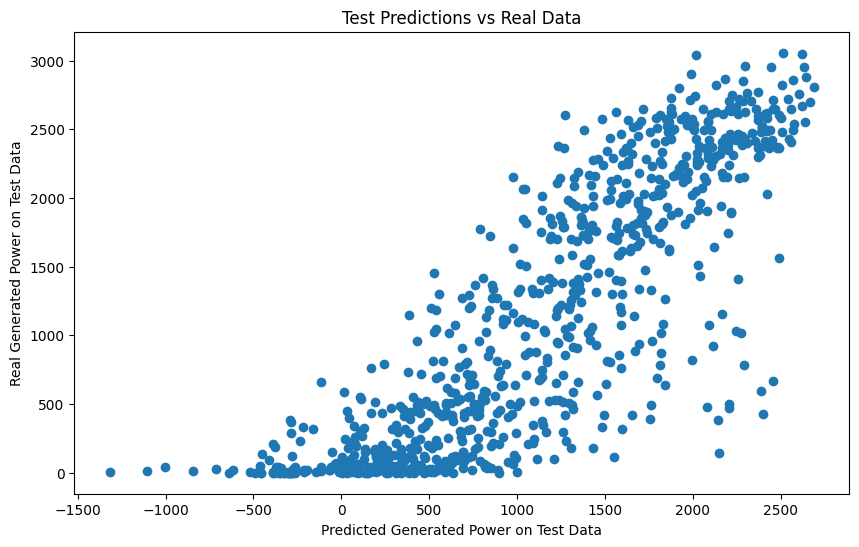

In [37]:
plt.figure(figsize=(10,6))
plt.scatter(y_pred, y_test)
plt.xlabel('Predicted Generated Power on Test Data')
plt.ylabel('Real Generated Power on Test Data')
plt.title('Test Predictions vs Real Data')